# Seed 44 advertising spike: aggregate replay


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "reported_runs/analysis/packaged.py").is_file())
sys.path.insert(0, str(repo)) if str(repo) not in sys.path else None
from reported_runs.analysis.presentation import load_results, NotebookReport, label_conditions
from reported_runs.analysis.packaged import derived_frame, bundle_provenance
from reported_runs.analysis.plotting import trajectory_grid, effect_grid, rank_grid, association_grid
%matplotlib inline
results = load_results()
report = NotebookReport(results, 'rq1_spike')
sources = results["sources"]
trajectory = label_conditions(results["trajectory"])
summaries = results["summaries"]
effect_summaries = results["effect_summaries"]
scales = report.scales

## Sponsored impressions and clicks


In [2]:
labels = {'O1_static_ad': 'Static advertising', 'O2_adaptive_ad_three_strike': 'L5 adaptive advertising'}
delivery = results['advertising'].loc[results['advertising'].seed.eq(44) & results['advertising'].population_seed.eq(18844) & results['advertising'].condition_id.isin(labels)].copy()
delivery = delivery.assign(condition=delivery.condition_id.map(labels), shown=delivery.sponsored_exposures, clicks=delivery.sponsored_clicks)
delivery['rate'] = delivery.clicks / delivery.shown.where(delivery.shown.gt(0))
assert len(delivery) == 60
peak = delivery.loc[delivery.iteration.isin([1, 5]), ['iteration', 'condition', 'shown', 'clicks', 'rate']].sort_values(['iteration', 'condition'])
report.table(peak, 'rq1_spike_counts', "", source_frame=delivery)

,iteration,condition,shown,clicks,rate
0,1,L5 adaptive advertising,150,52,0.346667
1,1,Static advertising,150,61,0.406667
2,5,L5 adaptive advertising,13,2,0.153846
3,5,Static advertising,150,48,0.32


LaTeX label: `chap:results:tab:rq1_spike_counts` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq1_spike_counts.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq1_spike_counts.csv)

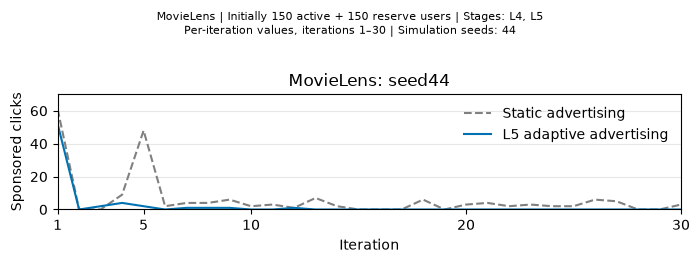

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq1_spike_sponsored_clicks.pdf) · [PNG](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq1_spike_sponsored_clicks.png) · label `chap:results:fig:rq1_spike_sponsored_clicks`

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7.1, 2.8))
for name, colour, linestyle in [('Static advertising', '#808080', '--'), ('L5 adaptive advertising', '#0072B2', '-')]:
    line = delivery.loc[delivery.condition.eq(name)]
    ax.plot(line.iteration, line.clicks, color=colour, linestyle=linestyle, label=name)
ax.set(xlim=(1, 30), ylim=(0, 70), xticks=[1, 5, 10, 20, 30], yticks=[0, 20, 40, 60], xlabel='Iteration', ylabel='Sponsored clicks', title='MovieLens: seed44')
ax.grid(axis='y', alpha=.3)
ax.legend(frameon=False)
fig.tight_layout()
report.figure(fig, delivery, 'rq1_spike_sponsored_clicks', "")

## Saved reasoning and context diagnostics


In [4]:
mentions = derived_frame('spike_reason_keyword_counts')
report.table(mentions, 'rq1_spike_reason_keywords', "")
context = bundle_provenance()['spike']
report.table(pd.DataFrame([{'Diagnostic': 'Static sponsor clickers', 'Count': context['static_clickers']}, {'Diagnostic': 'No other item with the full original tag combination', 'Count': context['static_clickers_without_other_full_tag_match']}, {'Diagnostic': 'Also clicked the iteration1 sponsor', 'Count': context['static_clickers_also_clicked_iteration1_sponsor']}]), 'rq1_spike_context', "")

,Reason mentions,Static reasons,Total reasons
0,Crime or noir,48,48
1,Thriller or suspense,46,48
2,"Character, motive, or psychological",33,48
3,"Moral, ethical, or consequences",32,48


LaTeX label: `chap:results:tab:rq1_spike_reason_keywords` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq1_spike_reason_keywords.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq1_spike_reason_keywords.csv)

,Diagnostic,Count
0,Static sponsor clickers,48
1,No other item with the full original tag combi...,46
2,Also clicked the iteration1 sponsor,26


LaTeX label: `chap:results:tab:rq1_spike_context` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq1_spike_context.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq1_spike_context.csv)

## Withdrawal and matched first-iteration agreement


In [5]:
withdrawals = derived_frame('spike_withdrawal_counts')
agreement = derived_frame('spike_first_iteration_agreement')
report.table(withdrawals, 'rq1_spike_withdrawals', "")
report.table(agreement, 'rq1_spike_agreement', "")
report.table(pd.DataFrame([{'Iteration5 paired users': context['iteration5_users_in_both_runs'], 'Identical ordered slates': context['iteration5_equal_ordered_slates']}]), 'rq1_spike_later_context', "")

,Withdrawal effective,users,clicked_an_organic_item_on_all_three
0,4,87,79
1,5,50,47


LaTeX label: `chap:results:tab:rq1_spike_withdrawals` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq1_spike_withdrawals.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq1_spike_withdrawals.csv)

,Measure,Agreement count,Compared pairs,Agreement
0,"Same item, both clicked",107,136,0.786765
1,Same item or both no-click,109,150,0.726667
2,Same sponsored-click decision,129,150,0.86


LaTeX label: `chap:results:tab:rq1_spike_agreement` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq1_spike_agreement.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq1_spike_agreement.csv)

,Iteration5 paired users,Identical ordered slates
0,120,0


LaTeX label: `chap:results:tab:rq1_spike_later_context` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq1_spike_later_context.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq1_spike_later_context.csv)